### Задача № 2.9 (Биномиальное распределение)

**Условие:** В среднем 20% пакетов акций на аукционах продаются по первоначально заявленной цене. Найти вероятность того, что из 9 пакетов акций в результате торгов по первоначально заявленной цене: 
1) не будут проданы 5 пакетов; 
2) будет продано: а) менее 2 пакетов; б) не более 2 пакетов; в) хотя бы 2 пакета; г) наивероятнейшее число пакетов.

In [8]:
import numpy as np
from scipy.stats import binom, poisson, norm

# Задача 2.9 — формула Бернулли
n_29, p_29 = 9, 0.2

p_29_1 = binom.pmf(4, n_29, p_29)
p_29_a = binom.cdf(1, n_29, p_29)
p_29_b = binom.cdf(2, n_29, p_29)
p_29_v = binom.sf(1, n_29, p_29)
p_29_m1 = binom.pmf(1, n_29, p_29)
p_29_m2 = binom.pmf(2, n_29, p_29)

print(f'1) Не проданы 5 пакетов: {p_29_1:.6f}')
print(f'2а) Менее 2 продано: {p_29_a:.6f}')
print(f'2б) Не более 2: {p_29_b:.6f}')
print(f'2в) Хотя бы 2: {p_29_v:.6f}')
print(f'2г) Наивероятнейшее число:  1 и 2')
print(f'P(X=1)={p_29_m1:.6f}; P(X=2)={p_29_m2:.6f}')
print(f'Сумма вероятностей: {(p_29_m1+p_29_m2):.6f}\n')

assert np.isclose(p_29_a + p_29_v, 1)
assert np.isclose(p_29_m1, p_29_m2)

1) Не проданы 5 пакетов: 0.066060
2а) Менее 2 продано: 0.436208
2б) Не более 2: 0.738198
2в) Хотя бы 2: 0.563792
2г) Наивероятнейшее число:  1 и 2
P(X=1)=0.301990; P(X=2)=0.301990
Сумма вероятностей: 0.603980



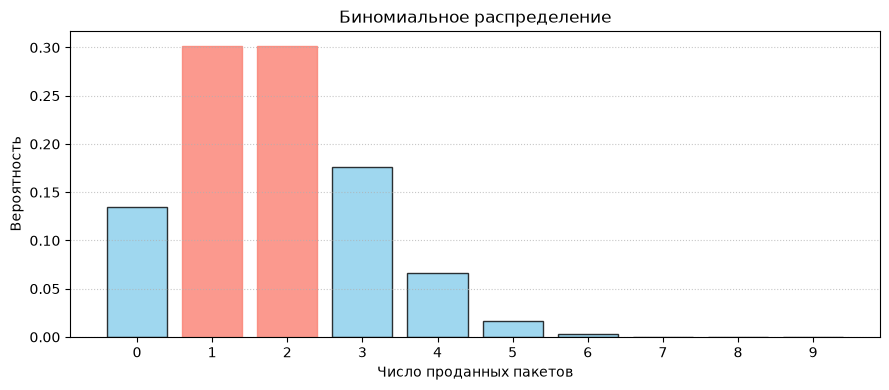

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom

# Параметры задачи 2.9
n_29, p_29 = 9, 0.2
k_values = np.arange(0, n_29 + 1)
probabilities = binom.pmf(k_values, n_29, p_29)

plt.figure(figsize=(9, 45//10))
bars = plt.bar(k_values, probabilities, color='skyblue', edgecolor='black', alpha=0.8)

bars[1].set_color('salmon')
bars[2].set_color('salmon')

plt.title('Биномиальное распределение', fontsize=12)
plt.xlabel('Число проданных пакетов', fontsize=10)
plt.ylabel('Вероятность', fontsize=10)
plt.xticks(k_values)
plt.grid(axis='y', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

### Задача № 2.10 (Формула Пуассона)

**Условие:** Завод отправил на базу 10 000 стандартных изделий. Среднее число изделий, повреждаемых при транспортировке, составляет 0,02%. Найти вероятность того, что из 10 000 изделий: 
1) будет повреждено: а) 3; б) по крайней мере 3; 
2) не будет повреждено: а) 9997; б) хотя бы 9997.

In [6]:
n_210, p_210 = 10000, 0.0002
lam_210 = n_210 * p_210

p_210_1a = poisson.pmf(3, lam_210)
p_210_1b = 1 - poisson.cdf(2, lam_210)
p_210_2a = poisson.pmf(3, lam_210)
p_210_2b = poisson.cdf(3, lam_210)

print(f'1а) Повреждено 3 изделия: {p_210_1a:.6f}')
print(f'1б) По крайней мере 3: {p_210_1b:.6f}')
print(f'2а) Не повреждено 9997: {p_210_2a:.6f}')
print(f'2б) Хотя бы 9997 целых: {p_210_2b:.6f}\n')

assert np.isclose(p_210_1a, p_210_2a)

1а) Повреждено 3 изделия: 0.180447
1б) По крайней мере 3: 0.323324
2а) Не повреждено 9997: 0.180447
2б) Хотя бы 9997 целых: 0.857123



### Задача № 2.11 (Интегральная и локальная теоремы Муавра-Лапласа)

**Условие:** По результатам проверок налоговыми инспекциями установлено, что в среднем каждое второе малое предприятие региона имеет нарушение финансовой дисциплины. Найти вероятность того, что из 1000 зарегистрированных в регионе малых предприятий имеют нарушения финансовой дисциплины: 
а) 480 предприятий; 
б) наивероятнейшее число предприятий; 
в) не менее 480; 
г) от 480 до 520.

In [9]:
n_211, p_211, q_211 = 1000, 0.5, 0.5
mu_211 = n_211 * p_211
sigma_211 = np.sqrt(n_211 * p_211 * q_211)

p_211_a = binom.pmf(480, n_211, p_211)
m0_211 = int(n_211 * p_211)
p_211_v = 1 - norm.cdf(479.5, loc=mu_211, scale=sigma_211)
p_211_g = norm.cdf(520.5, loc=mu_211, scale=sigma_211) - norm.cdf(479.5, loc=mu_211, scale=sigma_211)

print(f'а) Ровно 480 предприятий: {p_211_a:.6f}')
print(f'б) Наивероятнейшее число: {m0_211}')
print(f'в) Не менее 480: {p_211_v:.6f}')
print(f'г) От 480 до 520:  {p_211_g:.6f}')

assert 0 <= p_211_v <= 1
assert np.isclose(p_211_g + (1 - p_211_g), 1.0)

а) Ровно 480 предприятий: 0.011341
б) Наивероятнейшее число: 500
в) Не менее 480: 0.902604
г) От 480 до 520:  0.805208
